In [8]:
import os
import json
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from statsmodels.stats.multitest import multipletests
import statsmodels.formula.api as smf
from matplotlib.backends.backend_pdf import PdfPages
import warnings
from pathlib import Path

from statsmodels.formula.api import ols
import statsmodels.api as sm
import matplotlib.ticker as ticker
import statsmodels.api as sm
from scipy.stats import pearsonr

import sys 
sys.path.append('/root/capsule/code/figures') 
from core_utils import get_seaad_colors, get_tx_order

plt.rcParams['pdf.fonttype'] = 42 # ensures that the text is editable when imported into Illustrator


Functions

In [9]:
def compute_pairwise_group_interactions(data, depth_col, interaction_col, groups, features):
    """
    Compute pairwise group slope differences for each feature using
    depth x group interaction models.
    """

    all_results = []

    for feature in features:
        df_feat = data[[depth_col, interaction_col, feature]].dropna()
        if len(df_feat) < 5 or df_feat[feature].nunique() <= 1:
            continue

        pairwise_results = []

        # loop through each group (layer, subclass, supertype) as the reference
        for ref_group in groups:
            df_feat = df_feat.copy()
            df_feat[interaction_col] = pd.Categorical(df_feat[interaction_col], categories=groups)
            df_feat[interaction_col] = df_feat[interaction_col].cat.reorder_categories(
                [ref_group] + [l for l in groups if l != ref_group], ordered=True
            )

            model = smf.ols(f"{feature} ~ {depth_col} * {interaction_col}", data=df_feat).fit(cov_type='HC3')

            # extract interaction terms, ex: depth:layer[T.LayerX]
            for term in model.params.index:
                if f"{depth_col}:" in term:
                    comp_group = term.split('T.')[-1].replace(']', '')
                    pairwise_results.append({
                        'feature': feature,
                        'reference': ref_group,
                        'compare_to': comp_group,
                        'coef_diff': model.params[term],
                        'pval': model.pvalues[term],
                        'r_squared': model.rsquared,
                        'n': len(df_feat)
                    })

        # combine and apply FDR correction
        if pairwise_results:
            df_res = pd.DataFrame(pairwise_results)
            df_res['pval_fdr'] = multipletests(df_res['pval'], alpha=0.05, method='fdr_bh')[1]
            all_results.append(df_res)

    if not all_results:
        return None

    results_df = pd.concat(all_results, ignore_index=True)

    return results_df


In [10]:
def plot_feature_heatmaps(pairwise_df, fig_path, interaction_col, alpha=0.05):
    """
    For each feature, plot a heatmap of pairwise group slope differences.
    """
    features = pairwise_df['feature'].unique()
    groups = sorted(set(pairwise_df['reference']).union(pairwise_df['compare_to']))
    
    with PdfPages(fig_path) as pdf:
        with warnings.catch_warnings():
            warnings.simplefilter(action='ignore', category=FutureWarning)

        for feature in features:
            df_f = pairwise_df[pairwise_df['feature'] == feature]

            # create matrices for effect size and significance
            coef_matrix = pd.DataFrame(np.nan, index=groups, columns=groups)
            sig_mask = pd.DataFrame(False, index=groups, columns=groups)

            for _, row in df_f.iterrows():
                coef_matrix.loc[row['reference'], row['compare_to']] = row['coef_diff']
                sig_mask.loc[row['reference'], row['compare_to']] = row['pval_fdr'] > alpha

            # make it symmetric (optional)
            for i in groups:
                for j in groups:
                    if pd.isna(coef_matrix.loc[i, j]) and not pd.isna(coef_matrix.loc[j, i]):
                        coef_matrix.loc[i, j] = -coef_matrix.loc[j, i]
                        sig_mask.loc[i, j] = sig_mask.loc[j, i]

            #plot all, annotate signif:
            # annot_matrix = coef_matrix.round(2).astype(str)
            # annot_matrix[sig_mask == False] = annot_matrix[sig_mask == False] + '*'  # add star for significant
            # sns.heatmap(coef_matrix, annot=annot_matrix, fmt='', cmap='RdBu', center=0)

            #mask out non-signif:

            # Check if all off-diagonal cells are masked
            off_diag_mask = ~np.eye(len(sig_mask), dtype=bool)
            if sig_mask.values[off_diag_mask].all():
                # print(f"All off-diagonal values for feature '{feature}' are masked. Skipping plot.")
                continue

            fig = plt.figure(figsize=(6, 5))
            sns.heatmap(
                coef_matrix, 
                mask=sig_mask, 
                cmap='RdBu', 
                center=0, 
                annot=False, #True, 
                fmt=".2f", 
                cbar_kws={'label': 'Slope difference'},
                # annot_kws={"size": 8}  # set annotation font size
            )
            plt.title(f"{feature}\nPairwise {interaction_col.replace('_', '-')} slope differences (FDR < {alpha})")
            plt.xlabel("Comparison")
            plt.ylabel("Reference")

            pdf.savefig(fig, bbox_inches='tight')
            plt.close(fig)


In [11]:
def plot_significance_summary(pairwise_df, modality, interaction_col, alpha=0.05):
    """
    Create a summary heatmap showing the fraction of significant features
    for each group pair (after FDR correction).
    """
    groups = sorted(set(pairwise_df['reference']).union(pairwise_df['compare_to']))
    sig_matrix = pd.DataFrame(0.0, index=groups, columns=groups)
    n_features = pairwise_df['feature'].nunique()

    for (ref, comp), group in pairwise_df.groupby(['reference', 'compare_to']):
        frac_sig = len(group[group.pval_fdr < alpha]) / len(group)
        sig_matrix.loc[ref, comp] = frac_sig

    # make it symmetric
    for i in groups:
        for j in groups:
            if sig_matrix.loc[i, j] == 0 and sig_matrix.loc[j, i] != 0:
                sig_matrix.loc[i, j] = sig_matrix.loc[j, i]

    #mask upper triangle
    mask = np.triu(np.ones(sig_matrix.shape, dtype=bool), k=1)

    fig = plt.figure(figsize=(6, 5))
    sns.heatmap(
        sig_matrix, 
        cmap='rocket', 
        vmin=0, 
        # vmax=1, 
        annot=False, 
        fmt=".2f", 
        cbar_kws={'label': 'Fraction of significant features'},
        square=True, 
        mask=mask
    )
    plt.title(f"{modality.capitalize()} — {interaction_col.replace('_', '-')}\nFraction of significant slope differences\n(FDR < {alpha}, N={n_features} features)")
    plt.xlabel("Comparison")
    plt.ylabel("Reference")
    plt.show()

    return fig


In [12]:
def AOV_Two_mixed(flist,a,b,df):

    #saves results as one df
    all_results = []  
    for f in flist:
        model = ols(f'{f} ~ C({a}) + ({b}) + C({a}):({b})', data=df).fit()
        anova_table = sm.stats.anova_lm(model, typ=2)
        anova_table["feature"] = f  
        all_results.append(anova_table)

    # combine all into one DataFrame
    ANOVA_results = pd.concat(all_results, keys=flist).reset_index(level=1).reset_index(drop=True)
    ANOVA_results = ANOVA_results.rename(columns={'level_1' : 'level'})
    ANOVA_results = ANOVA_results[['feature', 'level', 'sum_sq', 'df', 'F', 'PR(>F)']]

    # Apply FDR correction on the p-values
    # 'PR(>F)' column contains the p-values
    pvals = ANOVA_results['PR(>F)'].values

    # Only keep non-NaN p-values for correction
    valid = ~np.isnan(pvals)
    pvals_valid = pvals[valid]

    # Perform FDR correction on valid p-values
    reject, pvals_fdr, _, _ = multipletests(pvals_valid, alpha=0.05, method='fdr_bh')

    # Create a full array of NaNs and fill corrected values
    pvals_fdr_full = np.full_like(pvals, np.nan, dtype=float)
    pvals_fdr_full[valid] = pvals_fdr

    # Add to DataFrame
    ANOVA_results['PR(>F)_FDR'] = pvals_fdr_full

    return ANOVA_results


Params

In [13]:
morpho_feature_type = 'dendrite' #dendrite, axon 
acute_only = False

In [14]:
# Transcriptomic label columns 
class_col =    'class_label_Hierarchical'
subclass_col = 'subclass_label_Hierarchical'
cluster_col =  'cluster_label_Hierarchical'

# Save root 
out_dir = Path('/root/capsule/scratch') / '20260807' / 'depth_interaction' / morpho_feature_type
if acute_only: 
    out_dir = out_dir / 'acute_only'
os.makedirs(out_dir, exist_ok=True)

# Data paths
DATA_ROOT = Path('/root/capsule/data')

#Metadata 
metadata_path =               DATA_ROOT / 'human'            / 'metadata'   / '20260807' / 'human_metadata.csv'
l23_ttype_rename_file =       DATA_ROOT / 'formatting_dicts' / 'L23_ttype_rename.json'
ttype_layer_file =            DATA_ROOT / 'formatting_dicts' / 'ttype_layer_dict.json'
ttype_subclass_file =         DATA_ROOT / 'formatting_dicts' / 'ttype_subclass_dict.json'
subclass_order_file =         DATA_ROOT / 'formatting_dicts' / 'subclass_order.txt'
ttype_order_file =            DATA_ROOT / 'formatting_dicts' / 'ttype_order.txt'
layer_color_file =            DATA_ROOT / 'colors'           / 'layer_colors.json'

#Morphology 
morpho_data_dend_root =      DATA_ROOT / 'human' / 'morphology' / 'dendrite' / '20260712'
morpho_data_axon_root =      DATA_ROOT / 'human' / 'morphology' / 'axon'     / '20260715'
if morpho_feature_type == 'dendrite': 
    morpho_data_root = morpho_data_dend_root
else:
    morpho_data_root = morpho_data_axon_root
morpho_feature_rename_file = DATA_ROOT / 'formatting_dicts' / 'morpho_feature_rename.csv'

#Electrophysiology
ephys_path =                DATA_ROOT / 'human' / 'electrophysiology' / 'features' / '20260807' / 'ephys_features.csv'
ephys_feature_rename_file = DATA_ROOT / 'formatting_dicts' / 'ephys_feature_rename.csv'


In [15]:
with open(ttype_layer_file, "r") as f:
    ttype_to_layer_dict = json.load(f)

with open(l23_ttype_rename_file, "r") as f:
    L23_ttype_rename_dict = json.load(f)

with open(layer_color_file) as f:
    layer_color_dict = json.load(f)

metadata = pd.read_csv(metadata_path)
metadata = metadata[ (metadata['Morphology'] == True) | (metadata['Electrophysiology'] == True)]
metadata.set_index('cell_id', inplace=True)
metadata[cluster_col] = metadata[cluster_col].replace('L5 ET_ME', 'L5 ET(ME)')
metadata[subclass_col] = metadata[subclass_col].replace('L5 ET_ME', 'L5 ET')
metadata[subclass_col] = metadata[subclass_col].replace('L5 ET(ME)', 'L5 ET')

m_features = pd.read_csv(os.path.join(morpho_data_root, 'RawFeatureWide.csv'), index_col='specimen_id')

e_features = pd.read_csv(ephys_path, index_col='specimen_id')
e_meta_cols = [subclass_col, cluster_col, 'depth_from_pia_norm']
e_features = e_features.drop(columns=e_meta_cols)

m_data = m_features.merge(metadata[[subclass_col, cluster_col, 'depth_from_pia_norm', 'paradigm']], left_index=True, right_index=True)
e_data = e_features.merge(metadata[[subclass_col, cluster_col, 'depth_from_pia_norm', 'paradigm']], left_index=True, right_index=True)

m_data = m_data[~m_data.depth_from_pia_norm.isna()]
e_data = e_data[~e_data.depth_from_pia_norm.isna()]

m_data[cluster_col] = m_data[cluster_col].apply(lambda x: L23_ttype_rename_dict.get(x, x))
e_data[cluster_col] = e_data[cluster_col].apply(lambda x: L23_ttype_rename_dict.get(x, x))
m_data['layer'] = m_data[cluster_col].map(lambda x: ttype_to_layer_dict[x])
e_data['layer'] = e_data[cluster_col].map(lambda x: ttype_to_layer_dict[x])

if acute_only:
    e_data = e_data[e_data.paradigm == 'acute']

In [16]:
color_dict = get_seaad_colors()
ttype_order, subclass_order = get_tx_order()
group_order = {
    'subclass_label' : subclass_order,
    't_type' :  ttype_order, 
    'layer' : sorted(e_data.layer.unique())
}

compartment_column = {
    'apical' : 'apical_dendrite_total_length',
    'basal' : 'basal_dendrite_total_length',
    'neurite' : 'apical_basal_total_length'
}

tx_labels = {
    'subclass_label' : 'subclass',
    't_type' : 'ttype',
    'layer' : 'layer'
}

tx_column = {
    'subclass_label' : subclass_col,
    't_type' : cluster_col,
    'layer' : 'layer'
}

### Compute stats - difference in slope of OLS fit per various groupings --> layer, subclass, supertype

In [17]:
depth_column = 'depth_from_pia_norm'

interaction_modality_dfs = {}
for modality in ['ephys', 'morpho']:
    interaction_modality_dfs[modality] = {}
    
    if modality == 'morpho':
        feature_cols = m_features
        data = m_data
    elif modality == 'ephys':
        feature_cols = e_features
        data = e_data
    else:   
        raise ValueError(f'Unknown modality: {modality}')
    
    for interaction_column in group_order.keys():
        print(f'{modality} - {interaction_column}')
    
        pairwise_interactions = compute_pairwise_group_interactions(
            data=data, 
            depth_col=depth_column, 
            interaction_col=tx_column[interaction_column], 
            groups=group_order[interaction_column],
            features=feature_cols
        )
        pairwise_interactions.to_csv(os.path.join(out_dir, f"depth_x_{modality}_feature_pairwise_{interaction_column}_interaction.csv"), index=False)
        interaction_modality_dfs[modality][interaction_column] = pairwise_interactions

ephys - subclass_label


/opt/conda/lib/python3.10/site-packages/statsmodels/regression/linear_model.py:2014: RuntimeWarning: divide by zero encountered in divide
  self.het_scale = (self.wresid / (1 - h))**2
/opt/conda/lib/python3.10/site-packages/statsmodels/regression/linear_model.py:2014: RuntimeWarning: divide by zero encountered in divide
  self.het_scale = (self.wresid / (1 - h))**2
/opt/conda/lib/python3.10/site-packages/statsmodels/regression/linear_model.py:2014: RuntimeWarning: divide by zero encountered in divide
  self.het_scale = (self.wresid / (1 - h))**2


ephys - t_type


/opt/conda/lib/python3.10/site-packages/statsmodels/regression/linear_model.py:2014: RuntimeWarning: divide by zero encountered in divide
  self.het_scale = (self.wresid / (1 - h))**2
/opt/conda/lib/python3.10/site-packages/statsmodels/regression/linear_model.py:1971: RuntimeWarning: invalid value encountered in multiply
  scale[:, None] * self.model.pinv_wexog.T)
/opt/conda/lib/python3.10/site-packages/statsmodels/regression/linear_model.py:2014: RuntimeWarning: divide by zero encountered in divide
  self.het_scale = (self.wresid / (1 - h))**2
/opt/conda/lib/python3.10/site-packages/statsmodels/regression/linear_model.py:1971: RuntimeWarning: invalid value encountered in multiply
  scale[:, None] * self.model.pinv_wexog.T)
/opt/conda/lib/python3.10/site-packages/statsmodels/regression/linear_model.py:2014: RuntimeWarning: divide by zero encountered in divide
  self.het_scale = (self.wresid / (1 - h))**2
/opt/conda/lib/python3.10/site-packages/statsmodels/regression/linear_model.py:197

ephys - layer
morpho - subclass_label
morpho - t_type


/opt/conda/lib/python3.10/site-packages/statsmodels/regression/linear_model.py:2014: RuntimeWarning: divide by zero encountered in divide
  self.het_scale = (self.wresid / (1 - h))**2
/opt/conda/lib/python3.10/site-packages/statsmodels/regression/linear_model.py:1971: RuntimeWarning: invalid value encountered in multiply
  scale[:, None] * self.model.pinv_wexog.T)
/opt/conda/lib/python3.10/site-packages/statsmodels/regression/linear_model.py:2014: RuntimeWarning: divide by zero encountered in divide
  self.het_scale = (self.wresid / (1 - h))**2
/opt/conda/lib/python3.10/site-packages/statsmodels/regression/linear_model.py:1971: RuntimeWarning: invalid value encountered in multiply
  scale[:, None] * self.model.pinv_wexog.T)
/opt/conda/lib/python3.10/site-packages/statsmodels/regression/linear_model.py:2014: RuntimeWarning: divide by zero encountered in divide
  self.het_scale = (self.wresid / (1 - h))**2
/opt/conda/lib/python3.10/site-packages/statsmodels/regression/linear_model.py:197

morpho - layer


Plot heatmap per feature

In [18]:
for modality in ['ephys', 'morpho']:
    for interaction_column in group_order.keys():
        print(f'{modality} - {interaction_column}')

        fig_path = os.path.join(out_dir, f"{modality}_{interaction_column}_significance_by_feature.pdf")
        plot_feature_heatmaps(interaction_modality_dfs[modality][interaction_column], fig_path, interaction_column)


ephys - subclass_label
ephys - t_type
ephys - layer
morpho - subclass_label
morpho - t_type
morpho - layer


Plot the fraction of significantly different depth ~ feature relationships per layer pair

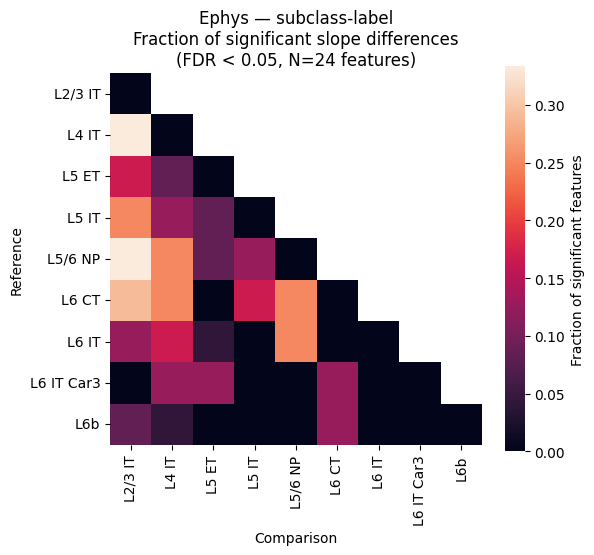

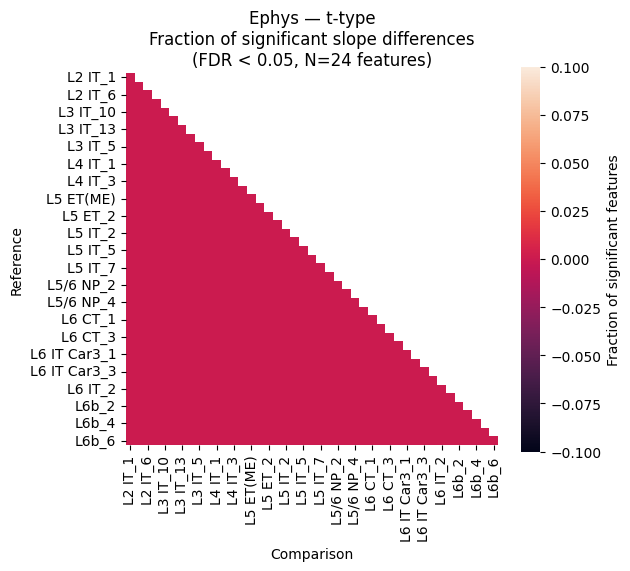

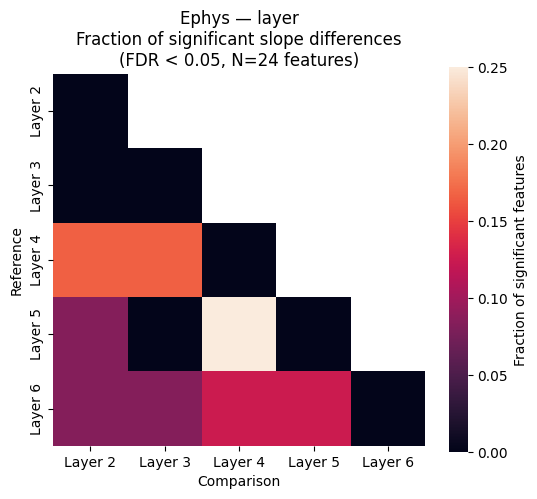

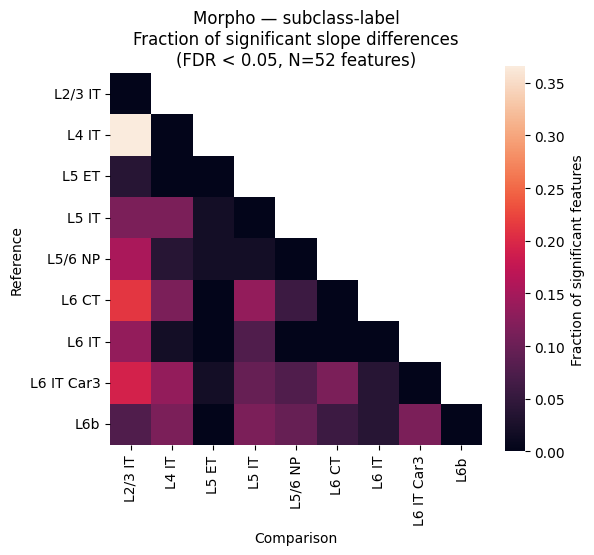

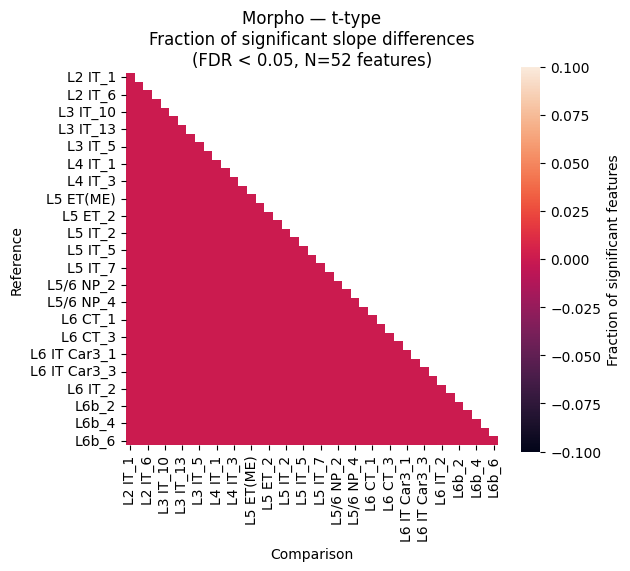

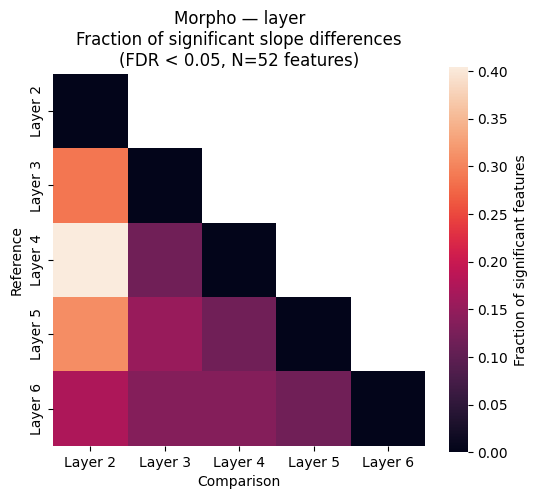

In [19]:
for modality in ['ephys', 'morpho']: 

    fig_path = os.path.join(out_dir, f"{modality}_interaction_significance_summary.pdf")
    with PdfPages(fig_path) as pdf:
        with warnings.catch_warnings():
            warnings.simplefilter(action='ignore', category=FutureWarning)

        for interaction_column in group_order.keys():
            fig = plot_significance_summary(interaction_modality_dfs[modality][interaction_column], modality, interaction_column)
            pdf.savefig(fig, bbox_inches='tight')

Plot scatters - L2, L3

Plot scatters - L5 subclasses (IT, ET, NP)

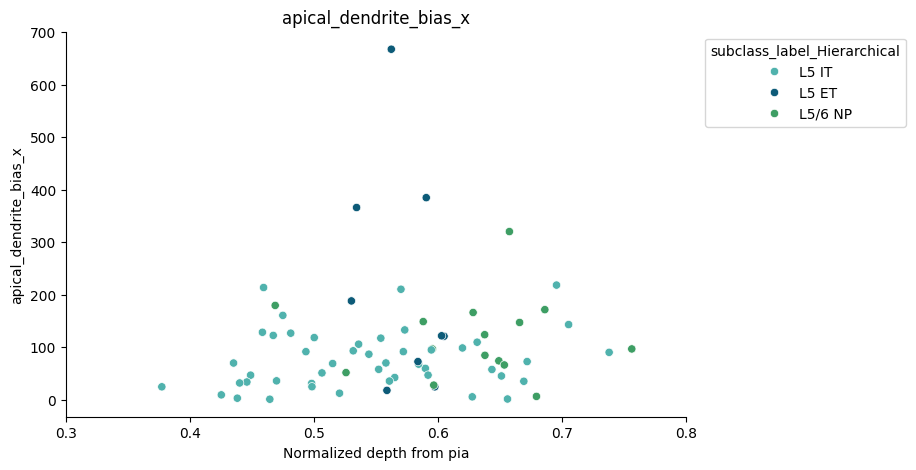

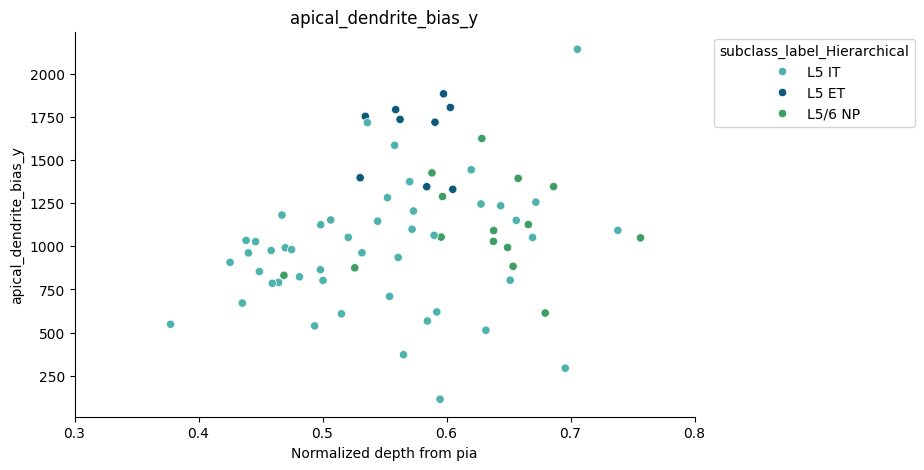

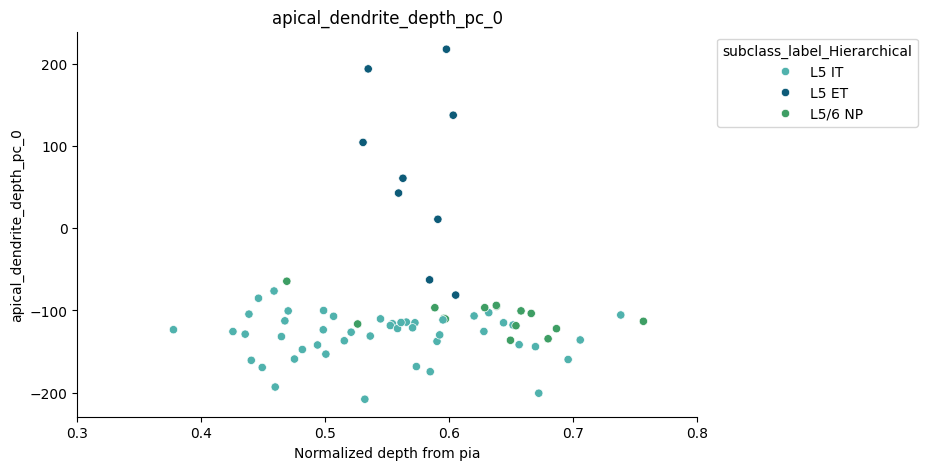

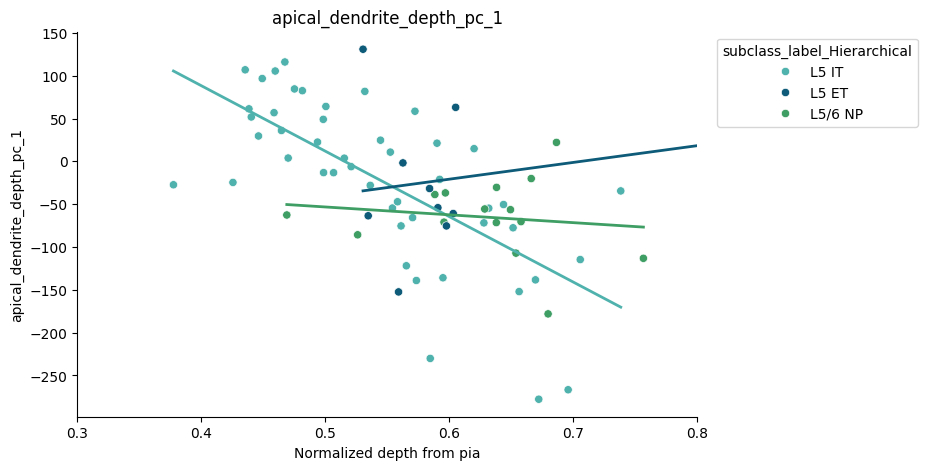

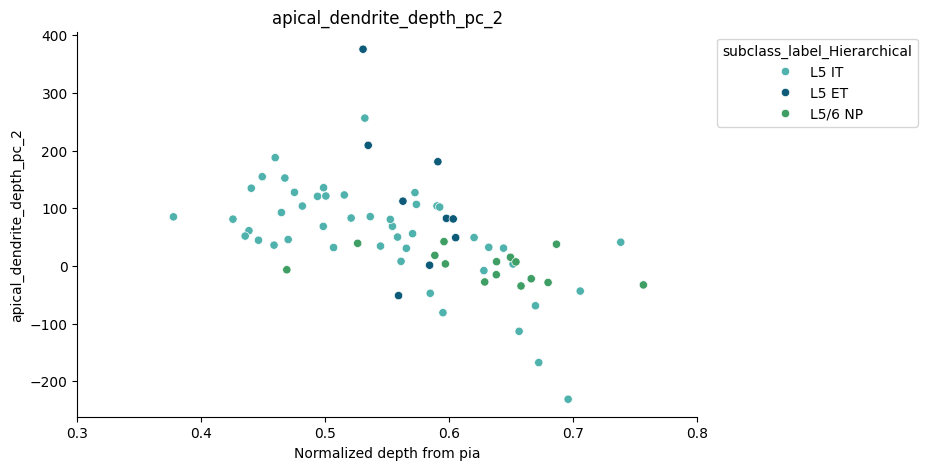

...

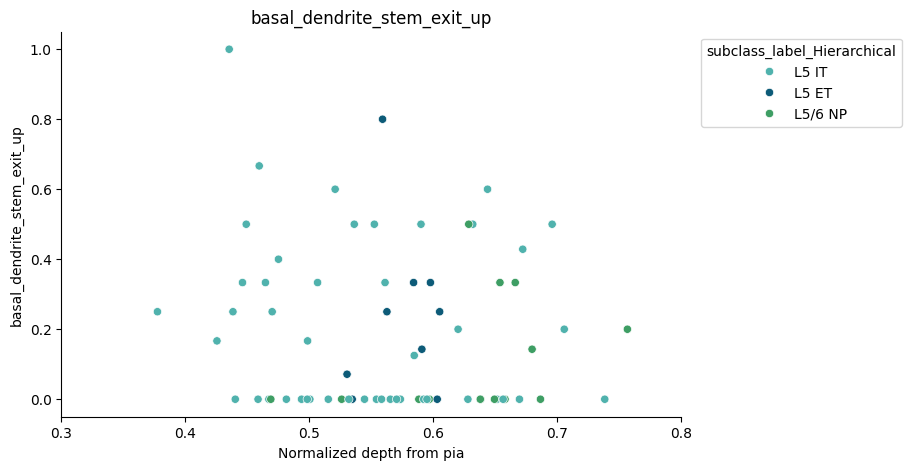

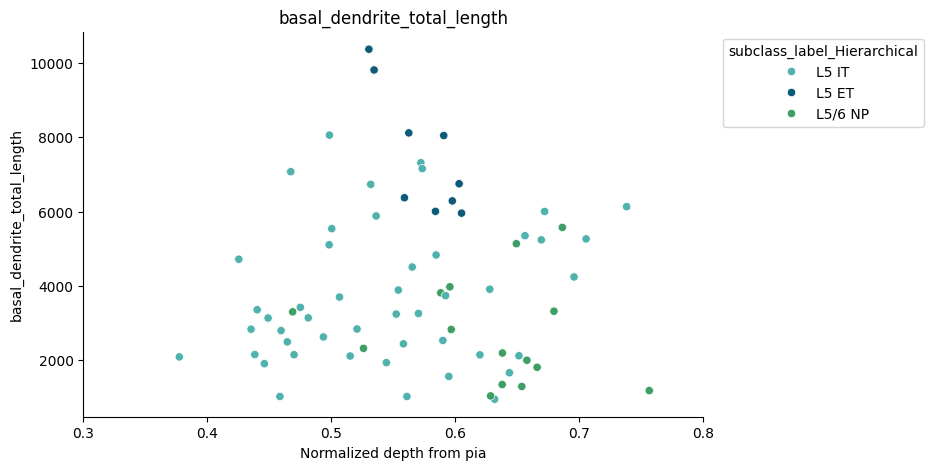

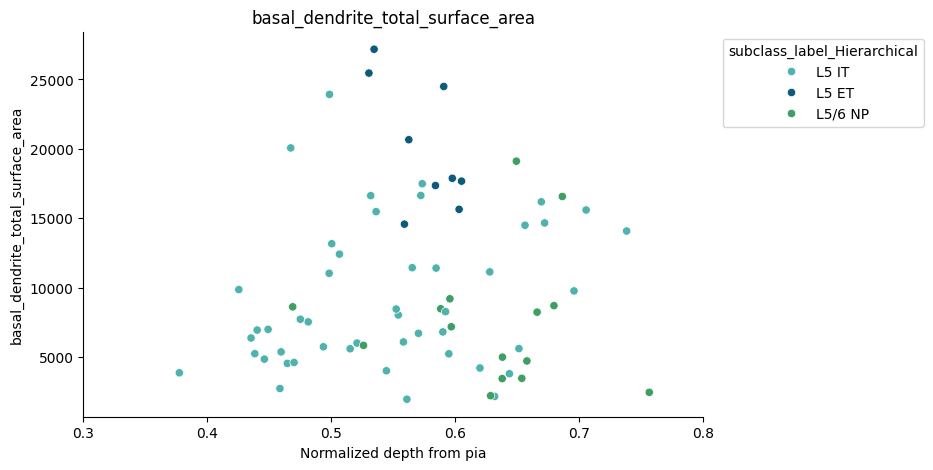

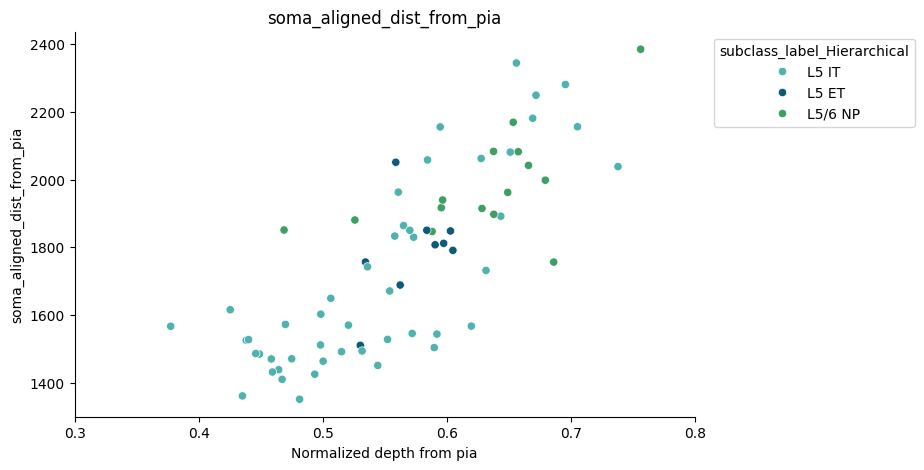

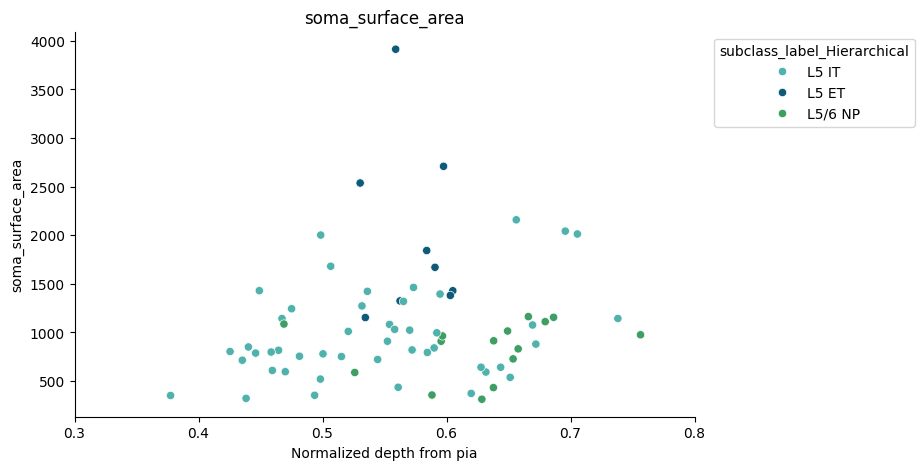

In [20]:
# Layer level plots

depth_column = 'depth_from_pia_norm'

group_order = ['L5 IT', 'L5 ET', 'L5/6 NP']
group_col = 'subclass_label'

for modality in ['morpho']: #, 'ephys']:
    
    if modality == 'morpho':
        feature_cols = m_features
        data = m_data
    elif modality == 'ephys':
        feature_cols = e_features
        data = e_data
    else:
        raise ValueError(f'Unknown modality: {modality}')
    
    stats_df = interaction_modality_dfs[modality][group_col]

    # Keep only the three subclasses
    data = data[data[subclass_col].isin(group_order)]

    # Keep comparisons among those three subclasses
    stats_df = stats_df[
        stats_df['reference'].isin(group_order) &
        stats_df['compare_to'].isin(group_order)
    ]

    fig_path = os.path.join(out_dir, f'{modality}_layer5_subclases_scatter_with_significantly_different_slopes.pdf')
    with PdfPages(fig_path) as pdf:
        with warnings.catch_warnings():
            warnings.simplefilter(action='ignore', category=FutureWarning)

        for feat in feature_cols[0:1]:

            fig, ax = plt.subplots(figsize=(8, 5))
            sns.scatterplot( data=data, x=depth_column, y=feat, hue=subclass_col, hue_order=group_order, palette=color_dict, ax=ax)
            sns.move_legend(ax, "upper left", bbox_to_anchor=(1.02, 1))

            feat_stats = stats_df[stats_df['feature'] == feat]

            # Plot lines if ANY pair of subclasses has significantly different slopes
            if (feat_stats['pval_fdr'] < 0.05).any():

                for group in group_order:
                    df_group = data[data[subclass_col] == group]

                    if len(df_group) > 2:
                        #plot regression lines per group
                        sns.regplot(
                            data=df_group,
                            x=depth_column,
                            y=feat,
                            scatter=False,
                            ci=None,
                            line_kws={
                                'lw': 2,
                                'color': color_dict[group]
                            }
                        )

            ax.set_title(f'{feat}')
            ax.set_xlabel('Normalized depth from pia')
            ax.set_ylabel(feat)
            ax.set_xlim((0.3, 0.8))
            sns.despine()
            pdf.savefig(fig, bbox_inches='tight')
            plt.show()


# Morpho and ephys features by soma depth 

Supertype

In [21]:
supertype_stats = {}
for modality in ['ephys', 'morpho']:
    supertype_stats[modality] = {}
    depth_column = 'depth_from_pia_norm'

    ########################################################

    if modality == 'morpho':
        feature_cols = m_features
        data = m_data
    elif modality == 'ephys':
        feature_cols = e_features
        data = e_data
    else:
        raise ValueError(f'Unknown modality: {modality}')

    for subclass in subclass_order:
        subclass_data = data[data[subclass_col] == subclass]
        supertypes = subclass_data[cluster_col].unique()

        results = []
        for supertype in supertypes:
            supertype_data = subclass_data[subclass_data[cluster_col] == supertype]

            for feature in feature_cols:
                df = supertype_data[[depth_column, feature]].dropna()
                if len(df) < 3:
                    continue
                if df[feature].nunique() == 1:
                    continue

                # feature ~ depth regression
                X = sm.add_constant(df[depth_column])
                y = df[feature]
                model = sm.OLS(y, X).fit(cov_type='HC3')
                f_pval = model.f_pvalue
                intercept, slope = model.params
                r_val, _ = pearsonr(df[depth_column], df[feature])

                results.append({
                    'subclass': subclass,
                    'supertype': supertype,
                    'feature': feature,
                    'num_cells': len(df),
                    'r': r_val,
                    'r_squared': model.rsquared,
                    'pval': f_pval,
                    'intercept': intercept, 
                    'slope': slope
                })

        # Convert to DataFrame
        results_df = pd.DataFrame(results)

        if not results_df.empty:
            # Apply FDR per supertype
            fdr_results = []
            for supertype in supertypes:
                df_sub = results_df[results_df['supertype'] == supertype].copy()
                if len(df_sub) == 0:
                    continue

                fdr_corrected = multipletests(df_sub['pval'], alpha=0.05, method='fdr_bh')
                df_sub['pval_fdr'] = fdr_corrected[1]

                fdr_results.append(df_sub)

            # Combine back
            results_df_fdr = pd.concat(fdr_results, ignore_index=True)
            results_df_fdr = results_df_fdr[
                ['subclass', 'supertype', 'feature', 'num_cells', 'r', 'r_squared', 'pval', 'pval_fdr', 'intercept', 'slope']
            ].sort_values(by=['subclass', 'supertype', 'pval_fdr'])

            supertype_stats[modality][subclass] = results_df_fdr

            # Save per subclass × modality
            out_path = os.path.join(out_dir, 'depth_x_{}_feature_stats_{}_supertypes.csv'.format(modality, subclass.replace('/', '-')))
            results_df_fdr.to_csv(out_path, index=False)


Subclass

In [22]:
subclass_stats = {}
for modality in ['ephys', 'morpho']:
    subclass_stats[modality] = {}
    depth_column = 'depth_from_pia_norm'

    if modality == 'morpho':
        feature_cols = m_features
        data = m_data
    elif modality == 'ephys':
        feature_cols = e_features
        data = e_data
    else:
        raise ValueError(f'Unknown modality: {modality}')
        
    results = []

    for subclass in subclass_order:
        subclass_data = data[data[subclass_col] == subclass]

        for feature in feature_cols:
            df = subclass_data[[depth_column, feature]].dropna()
            if len(df) < 3:
                continue
            if df[feature].nunique() == 1:
                continue

            # feature ~ depth regression
            X = sm.add_constant(df[depth_column])
            y = df[feature]
            model = sm.OLS(y, X).fit(cov_type='HC3')
            f_pval = model.f_pvalue
            intercept, slope = model.params
            r_squared = model.rsquared
            r_val, _ = pearsonr(df[depth_column], df[feature])

            model2 = sm.OLS(y, X).fit()
            f_pval_norm = model2.f_pvalue
            slope_pval = model2.pvalues[1]  # same as linregress

            results.append({
                'subclass': subclass,
                'feature': feature,
                'num_cells': len(df),
                'r': r_val,
                'r_squared': r_squared,
                'pval': f_pval,
                'intercept': intercept, 
                'slope': slope,
                'slope_pval' : slope_pval,
                'pval_no_hc3': f_pval_norm
            })

    # Convert to DataFrame
    results_df = pd.DataFrame(results)

    if not results_df.empty:
        # Apply FDR correction per subclass
        fdr_results = []
        for subclass in subclass_order:
            df_sub = results_df[results_df['subclass'] == subclass].copy()
            if len(df_sub) == 0:
                continue
            fdr_corrected = multipletests(df_sub['pval'], alpha=0.05, method='fdr_bh')
            df_sub['pval_fdr'] = fdr_corrected[1]

            fdr_corrected_no_hc3 = multipletests(df_sub['pval_no_hc3'], alpha=0.05, method='fdr_bh')
            df_sub['pval_fdr_no_hc3'] = fdr_corrected_no_hc3[1]
            fdr_results.append(df_sub)

        results_df_fdr = pd.concat(fdr_results, ignore_index=True)
        results_df_fdr = results_df_fdr[
            ['subclass', 'feature', 'num_cells', 'r', 'r_squared', 'pval', 'pval_fdr', 'intercept', 'slope'] #, 'pval_no_hc3', 'pval_fdr_no_hc3']
        ].sort_values(by=['subclass', 'pval_fdr'])

        subclass_stats[modality] = results_df_fdr

        results_df_fdr.to_csv(
            os.path.join(out_dir, f'depth_x_{modality}_feature_stats_subclass.csv'), 
            index=False
        )


Layer

In [23]:
layer_stats = {}
layer_order = ['Layer 2', 'Layer 3']
for modality in ['ephys', 'morpho']:
    layer_stats[modality] = {}
    depth_column = 'depth_from_pia_norm'

    if modality == 'morpho':
        feature_cols = m_features
        data = m_data
    elif modality == 'ephys':
        feature_cols = e_features
        data = e_data
    else:
        raise ValueError(f'Unknown modality: {modality}')
        
    results = []

    for layer in layer_order:
        layer_data = data[data['layer'] == layer]

        for feature in feature_cols:
            df = layer_data[[depth_column, feature]].dropna()
            if len(df) < 3:
                continue
            if df[feature].nunique() == 1:
                continue

            # feature ~ depth regression
            X = sm.add_constant(df[depth_column])
            y = df[feature]
            model = sm.OLS(y, X).fit(cov_type='HC3')
            f_pval = model.f_pvalue
            intercept, slope = model.params
            r_val, _ = pearsonr(df[depth_column], df[feature])

            results.append({
                'layer': layer,
                'feature': feature,
                'num_cells': len(df),
                'r': r_val,
                'r_squared': model.rsquared,
                'pval': f_pval,
                'intercept': intercept, 
                'slope': slope
            })

    # Convert to DataFrame
    results_df = pd.DataFrame(results)

    if not results_df.empty:
        # Apply FDR correction per layer
        fdr_results = []
        for layer in layer_order:
            df_sub = results_df[results_df['layer'] == layer].copy()
            if len(df_sub) == 0:
                continue
            fdr_corrected = multipletests(df_sub['pval'], alpha=0.05, method='fdr_bh')
            df_sub['pval_fdr'] = fdr_corrected[1]
            fdr_results.append(df_sub)

        results_df_fdr = pd.concat(fdr_results, ignore_index=True)
        results_df_fdr = results_df_fdr[
            ['layer', 'feature', 'num_cells', 'r', 'r_squared', 'pval', 'pval_fdr', 'intercept', 'slope']
        ].sort_values(by=['layer', 'pval_fdr'])

        layer_stats[modality] = results_df_fdr

        results_df_fdr.to_csv(
            os.path.join(out_dir, f'depth_x_{modality}_feature_stats_layer.csv'), 
            index=False
        )


# Multiclass regression with interaction

### L2 L3

Compute stats

In [24]:
continuous_col = 'depth_from_pia_norm'
categorical_col = 'layer'

multimodal_interaction_dfs = {}
for modality in ['ephys', 'morpho']:
    if modality == 'morpho':
        feature_cols = m_features
        data = m_data
    elif modality == 'ephys':
        feature_cols = e_features
        data = e_data
    else:   
        raise ValueError(f'Unknown modality: {modality}')
    
    data = data[data[categorical_col].isin(['Layer 2', 'Layer 3'])]
    modality_multimodal_interaction_df = AOV_Two_mixed(feature_cols, categorical_col, continuous_col, data)
    multimodal_interaction_dfs[modality] = modality_multimodal_interaction_df

    modality_multimodal_interaction_df.to_csv(os.path.join(out_dir, f'{modality}_Layer2_Layer3_multimodal_regression_with_interaction.csv'), index=False)


/opt/conda/lib/python3.10/site-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 1, but rank is 0
  warnings.warn('covariance of constraints does not have full '
/opt/conda/lib/python3.10/site-packages/statsmodels/base/model.py:1923: RuntimeWarning: invalid value encountered in divide
  F /= J
/opt/conda/lib/python3.10/site-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 1, but rank is 0
  warnings.warn('covariance of constraints does not have full '
/opt/conda/lib/python3.10/site-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 1, but rank is 0
  warnings.warn('covariance of constraints does not have full '


Plot scatters - plot all regression lines (solid if signif, dashed if not) and pval for the difference in slope

In [25]:
#Load the individual correlation data 
within_layer_stats = {}
for modality in ['ephys', 'morpho']:
    within_layer_stats[modality] = pd.read_csv(os.path.join(out_dir, f'depth_x_{modality}_feature_stats_layer.csv'))

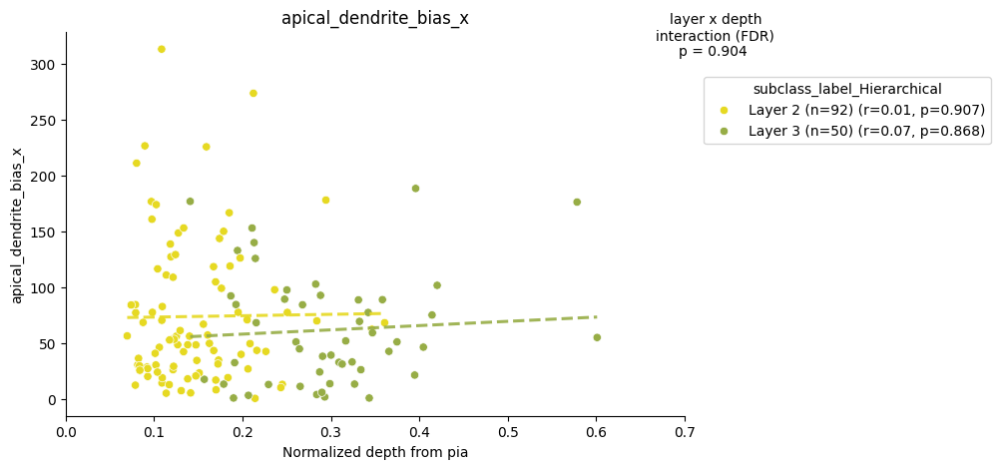

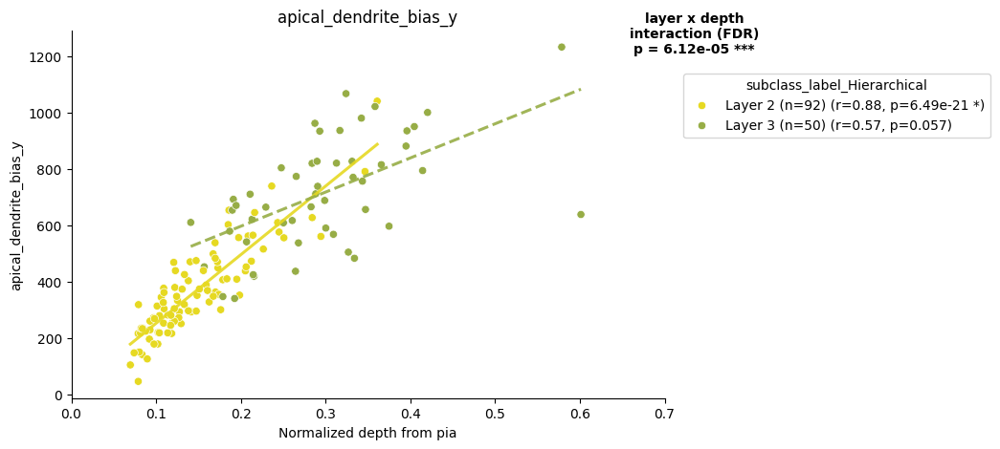

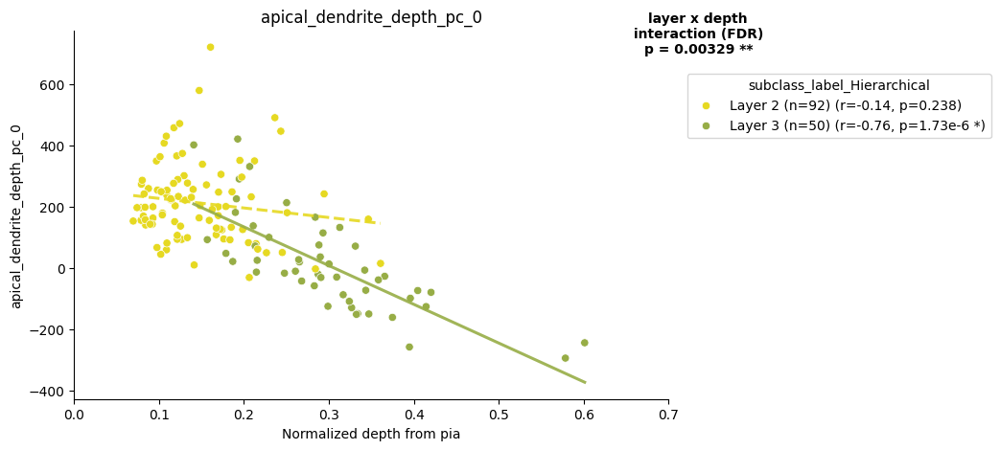

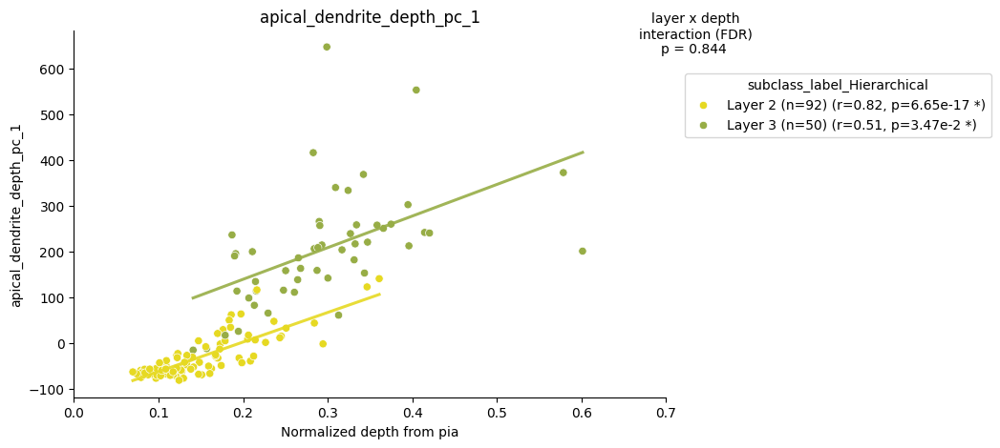

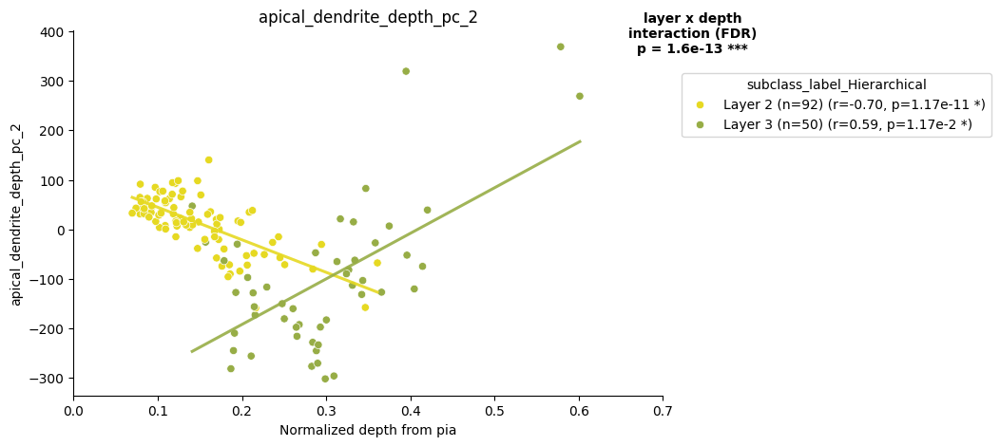

...

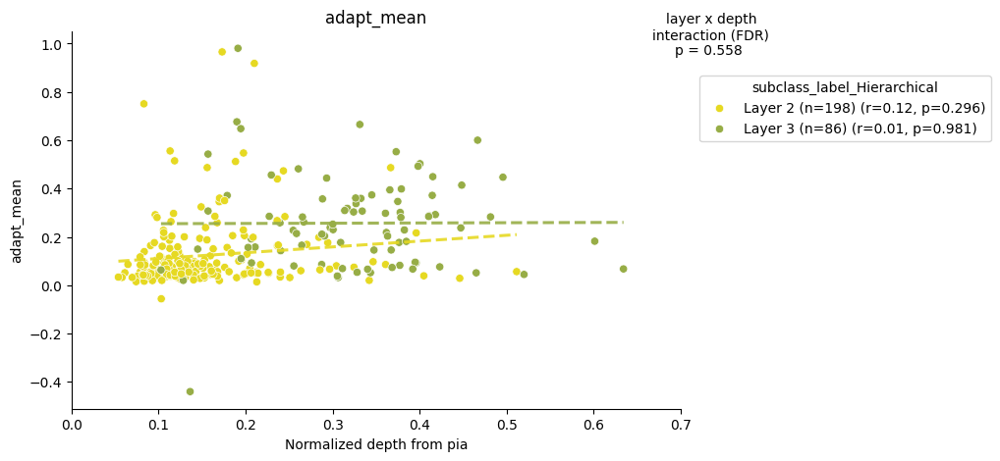

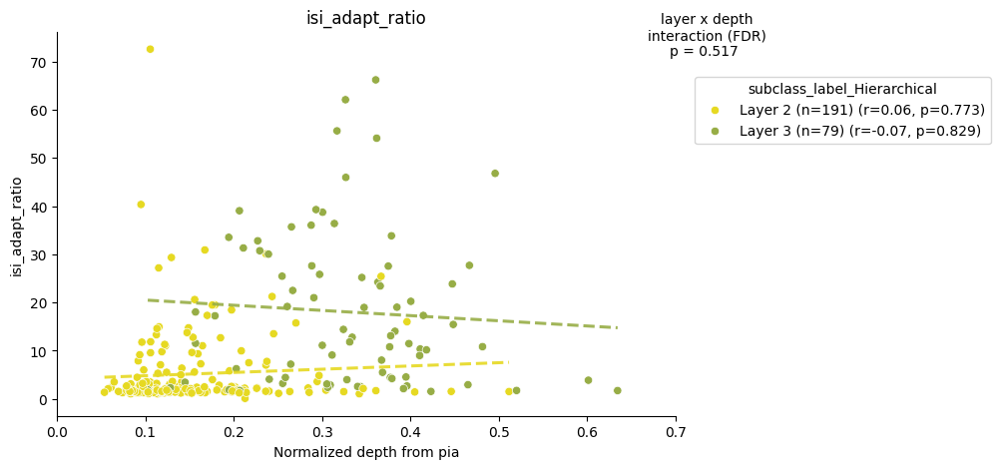

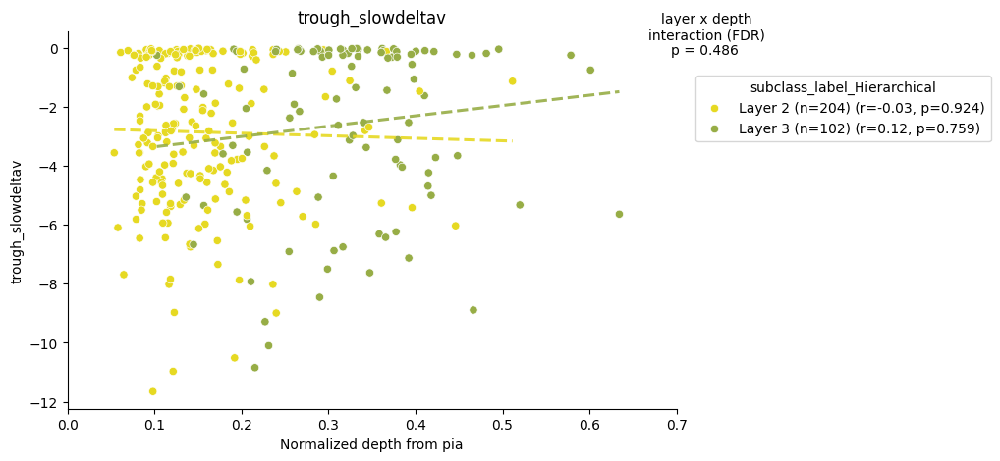

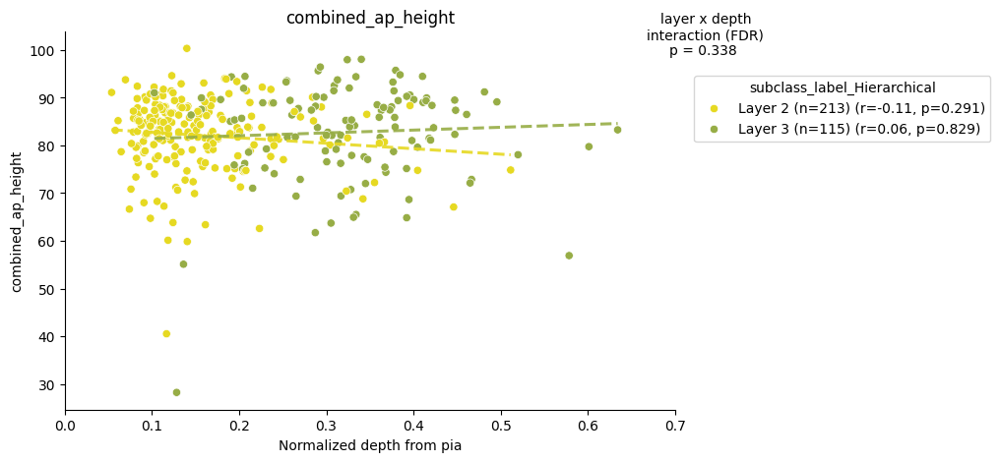

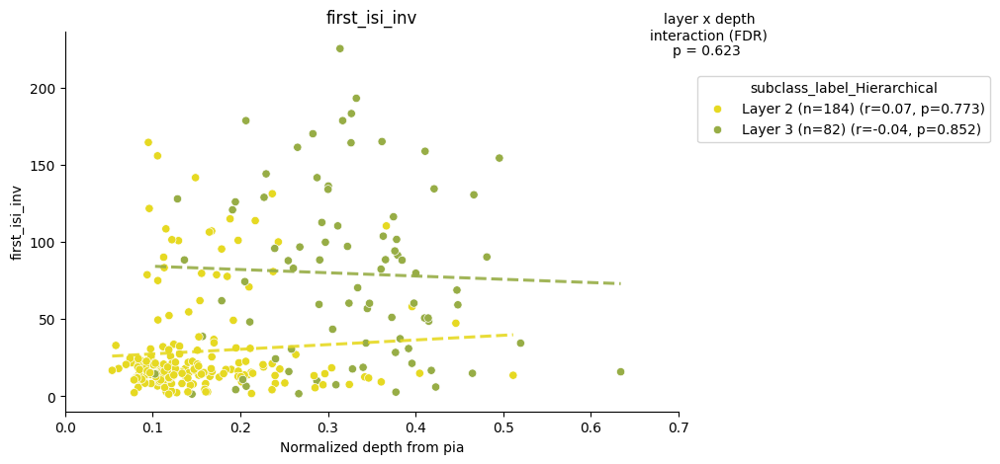

In [26]:
# Layer level plots

depth_column = 'depth_from_pia_norm'

layer_order = ['Layer 2', 'Layer 3'] #group_order['layer']
layer_col = 'layer'

layer_color_dict = {
    'Layer 2': "#E6D922",  # golden ochre
    'Layer 3': "#97AD46",  # botanical green
    'Layer 4': "#3DC2BB",  # turquoise
    'Layer 5': "#6195CF",  # periwinkle blue
    'Layer 6': "#A65FA1"   # orchid purple
}

for modality in ['morpho', 'ephys']:
    
    if modality == 'morpho':
        feature_cols = m_features
        data = m_data
    elif modality == 'ephys':
        feature_cols = e_features
        data = e_data
    else:
        raise ValueError(f'Unknown modality: {modality}')
    
    within_layer_stats_df = within_layer_stats[modality] #stats looking at if each layer regression line slope (correlation) is signif
    interaction_stats_df = multimodal_interaction_dfs[modality] #stats looking at if the depth~feature relationship is signif different between layers

    #just layer 2 and Layer 3 data
    data = data[data.layer.isin(['Layer 2', 'Layer 3'])]
    # interaction_stats_df = interaction_stats_df[(interaction_stats_df.reference == 'Layer 2') & (interaction_stats_df.compare_to == 'Layer 3')] # * (interaction_stats_df.pval_fdr < 0.05)]

    fig_path = os.path.join(out_dir, f'{modality}_layer2_layer3_scatter_all_regression_lines_with_significance_indicated.pdf')
    with PdfPages(fig_path) as pdf:
        with warnings.catch_warnings():
            warnings.simplefilter(action='ignore', category=FutureWarning)

        for feat in feature_cols:

            fig, ax = plt.subplots(figsize=(8, 5))
            sns.scatterplot( data=data, x=depth_column, y=feat, hue=layer_col, hue_order=layer_order, palette=layer_color_dict, ax=ax)

            legend_labels = {}
            for l in layer_order:                     
                legend_labels[l] = f"{l} (n={len(data[data['layer'] == l][[depth_column, feat]].dropna())})"

            #plot regression line (dashed if not signif)
            for _, row in within_layer_stats_df[(within_layer_stats_df.feature == feat) * (within_layer_stats_df.layer.isin(layer_order))].iterrows():
                layer = row['layer']
                intercept, slope = row['intercept'], row['slope']
                r = row['r']
                pval_fdr = row['pval_fdr']
                p_val_exp = int(np.floor(np.log10(pval_fdr)))  # Exponent of the p-value - for legend
                p_val_mant = pval_fdr / 10**p_val_exp  # Mantissa of the p-value - for legend

                # Get the original data points for this supertype
                data_points = data[(data['layer'] == layer)][[depth_column, feat]].dropna()
                n_cells = len(data_points)
                if n_cells < 3:
                    continue

                # Predict the regression line
                x_vals = np.linspace(data_points[depth_column].min(),
                                    data_points[depth_column].max(), 100)
                y_vals = intercept + slope * x_vals

                # plot
                color = layer_color_dict.get(layer, 'black')
                linestyle = '--' if pval_fdr >= 0.05 else '-'
                ax.plot(x_vals, y_vals, color=color, lw=2.2, alpha=0.9, linestyle=linestyle)
            
                if pval_fdr < 0.05: 
                    legend_labels[layer] = legend_labels[layer] + f" (r={r:.2f}, p={p_val_mant:.2f}e{p_val_exp} *)"
                else:
                    legend_labels[layer] = legend_labels[layer] + f" (r={r:.2f}, p={pval_fdr:.3f})"

            # Add annotation for interaction p-value
            comparison_pval = interaction_stats_df[(interaction_stats_df.feature == feat) &
                                                   (interaction_stats_df.level == 'C(layer):depth_from_pia_norm')]['PR(>F)_FDR'].values[0]
            signif = ""
            if comparison_pval < 0.001: signif = "***"
            elif comparison_pval < 0.01: signif = "**"
            elif comparison_pval < 0.05: signif = "*"
            ax.text(
                1.05, 1.05,
                f"layer x depth\ninteraction (FDR)\np = {comparison_pval:.3g} {signif}",
                transform=ax.transAxes,
                ha='center', va='top',
                fontsize=10, fontweight='bold' if signif else 'normal'
            )

            # Update legend labels
            handles, labels = ax.get_legend_handles_labels()
            new_labels = [legend_labels.get(lbl, lbl) for lbl in labels]
            ax.legend(handles, new_labels, title=subclass_col, bbox_to_anchor=(1.02, 0.9), loc='upper left')

            ax.set_title(f'{feat}')
            ax.set_xlabel('Normalized depth from pia')
            ax.set_ylabel(feat)
            ax.set_xlim((0, 0.7))
            sns.despine()
            pdf.savefig(fig, bbox_inches='tight')
            plt.show()


### L5 subclasses

In [27]:
continuous_col = 'depth_from_pia_norm'
categorical_col = subclass_col 

group_order = ['L5 IT', 'L5 ET', 'L5/6 NP']

multimodal_interaction_dfs = {}

for modality in ['ephys', 'morpho']:

    if modality == 'morpho':
        feature_cols = m_features
        data = m_data
    elif modality == 'ephys':
        feature_cols = e_features
        data = e_data
    else:
        raise ValueError(f'Unknown modality: {modality}')

    # Keep only the three L5 subclasses
    data = data[data[categorical_col].isin(group_order)].copy()

    # Run omnibus subclass x depth interaction ANOVA
    modality_multimodal_interaction_df = AOV_Two_mixed(
        feature_cols,
        categorical_col,
        continuous_col,
        data
    )

    multimodal_interaction_dfs[modality] = modality_multimodal_interaction_df

    modality_multimodal_interaction_df.to_csv(
        os.path.join(
            out_dir,
            f'{modality}_L5_subclasses_multimodal_regression_with_interaction.csv'
        ),
        index=False
    )

/opt/conda/lib/python3.10/site-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 2, but rank is 0
  warnings.warn('covariance of constraints does not have full '
/opt/conda/lib/python3.10/site-packages/statsmodels/base/model.py:1923: RuntimeWarning: invalid value encountered in divide
  F /= J
/opt/conda/lib/python3.10/site-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 1, but rank is 0
  warnings.warn('covariance of constraints does not have full '
/opt/conda/lib/python3.10/site-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 2, but rank is 0
  warnings.warn('covariance of constraints does not have full '


Plot scatters - L5 subclasses - plot all regression lines (solid if signif, dashed if not) and pval for the difference in slope

In [28]:
#Load the individual correlation data 
within_subclass_stats = {}
for modality in ['ephys', 'morpho']:
    within_subclass_stats[modality] = pd.read_csv(os.path.join(out_dir, f'depth_x_{modality}_feature_stats_subclass.csv'))

In [29]:
m_data.subclass_label_Hierarchical.value_counts()

L2/3 IT       142
L4 IT          68
L5 IT          47
L6 IT Car3     17
L5/6 NP        15
L6 IT          13
L5 ET          10
L6 CT           9
L6b             6
Name: subclass_label_Hierarchical, dtype: int64

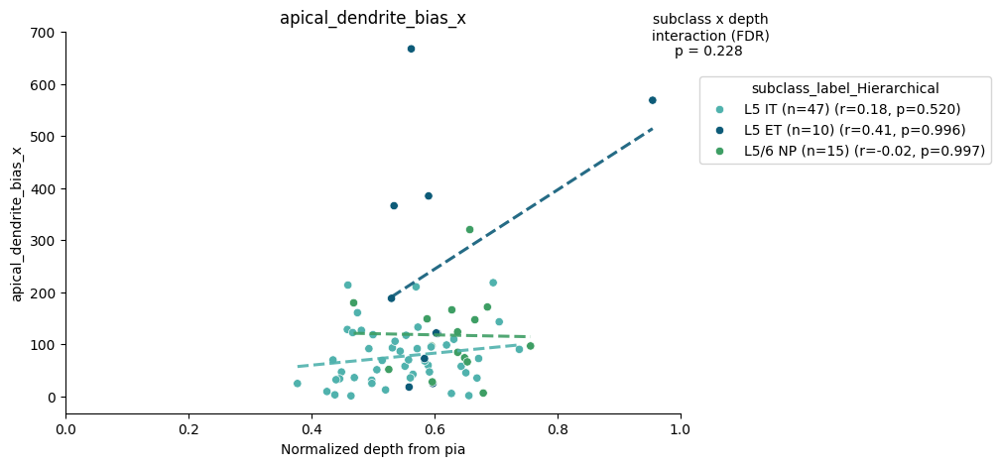

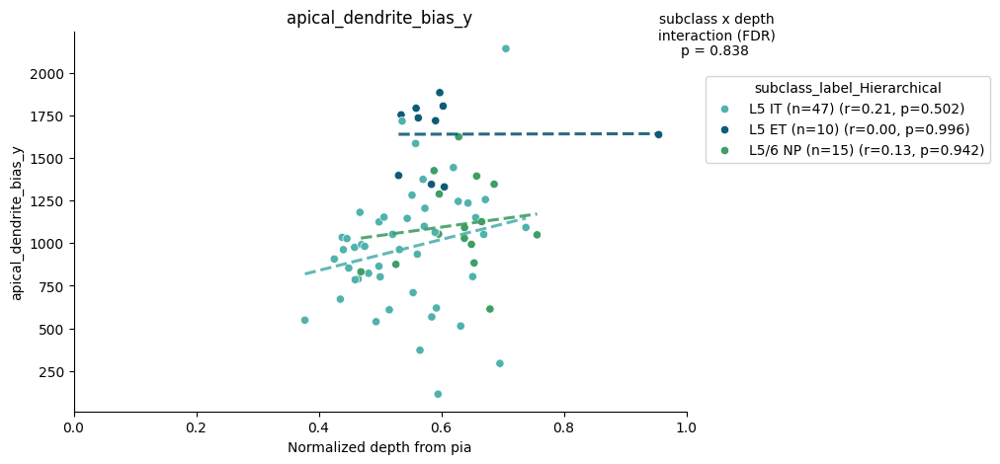

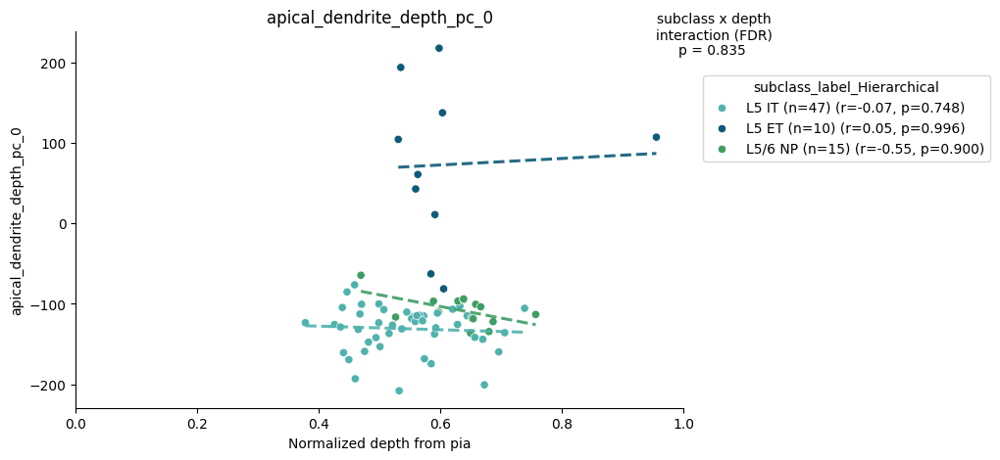

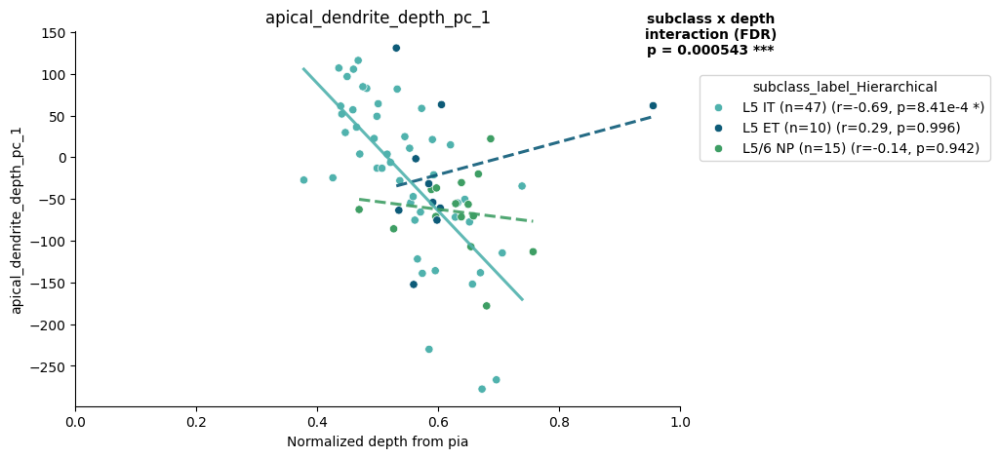

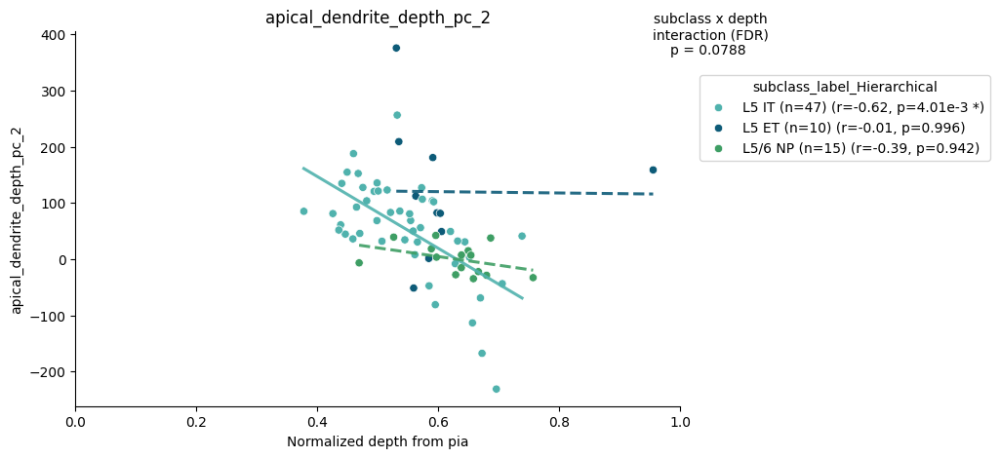

...

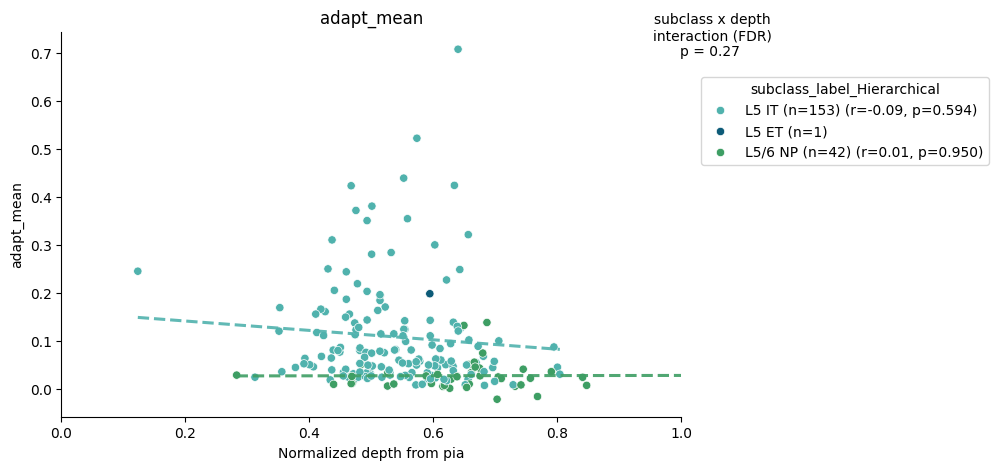

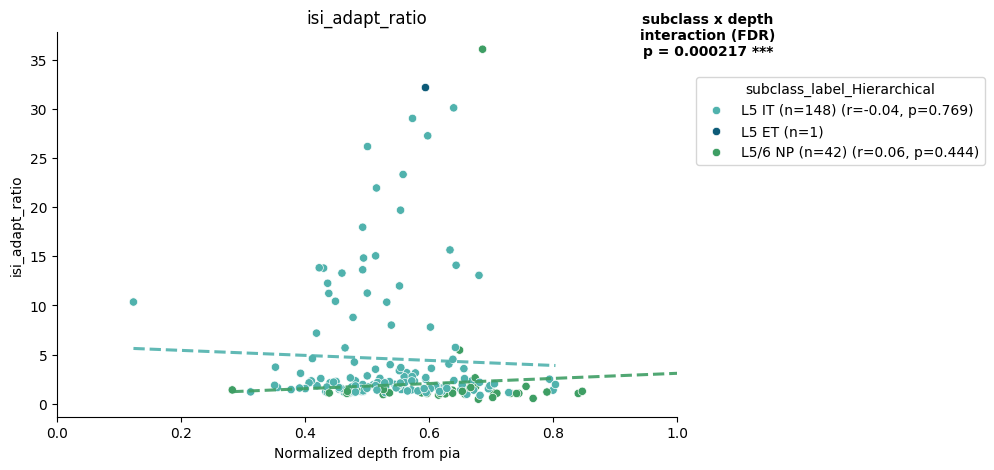

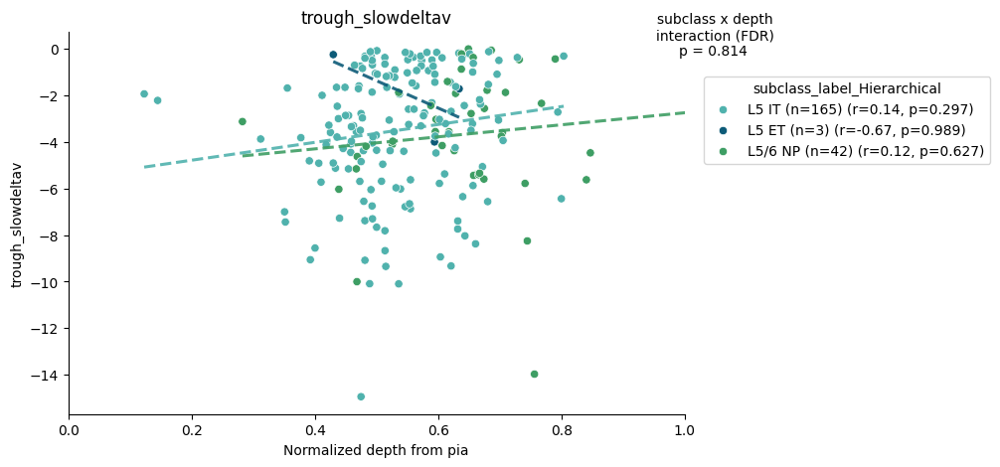

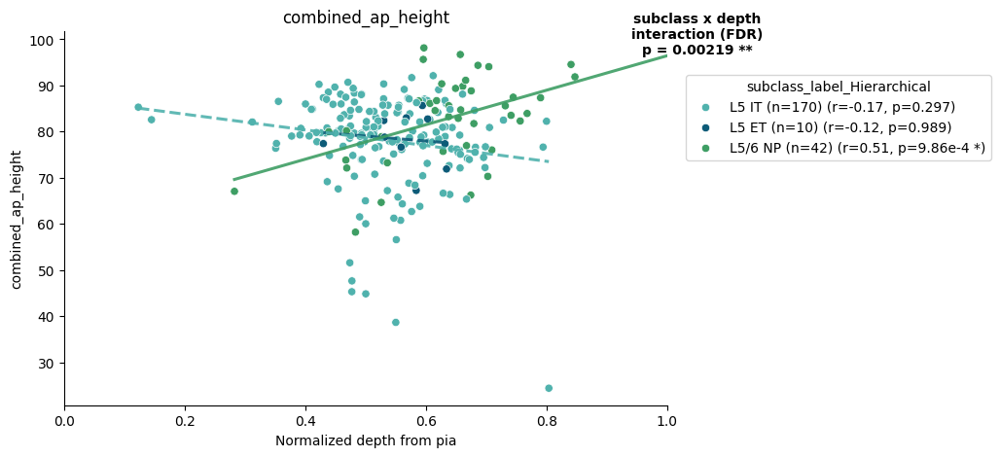

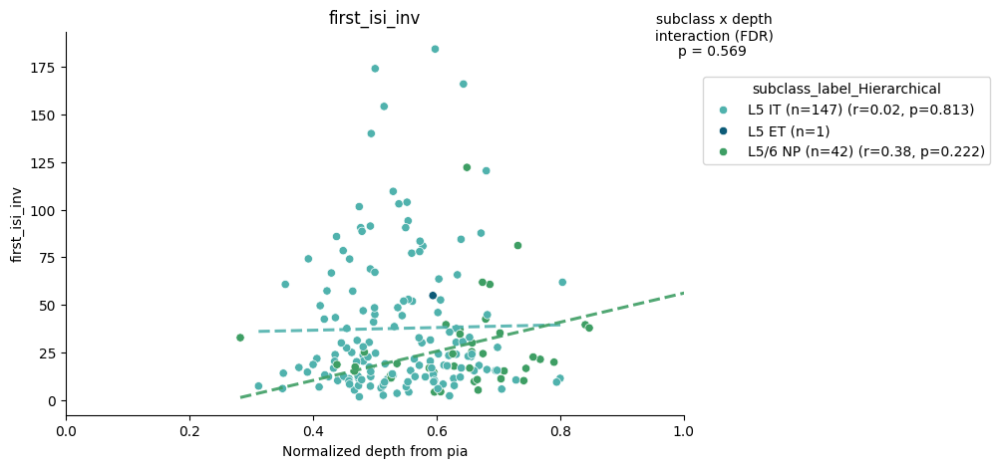

In [30]:
# L5 subclass level plots

depth_column = 'depth_from_pia_norm'

group_order = ['L5 IT', 'L5 ET', 'L5/6 NP']
group_col = subclass_col

for modality in ['morpho', 'ephys']:
    
    if modality == 'morpho':
        feature_cols = m_features
        data = m_data
    elif modality == 'ephys':
        feature_cols = e_features
        data = e_data
    else:
        raise ValueError(f'Unknown modality: {modality}')
    
    within_subclass_stats_df = within_subclass_stats[modality] # stats looking at if each subclass regression line slope (correlation) is signif
    interaction_stats_df = multimodal_interaction_dfs[modality] # stats looking at if the depth~feature relationship is signif different between subclasses

    # Keep only the three L5 subclasses
    data = data[data[group_col].isin(group_order)]

    fig_path = os.path.join(out_dir, f'{modality}_L5_subclasses_scatter_all_regression_lines_with_significance_indicated.pdf')
    with PdfPages(fig_path) as pdf:
        with warnings.catch_warnings():
            warnings.simplefilter(action='ignore', category=FutureWarning)

        for feat in feature_cols:

            fig, ax = plt.subplots(figsize=(8, 5))
            sns.scatterplot(data=data, x=depth_column, y=feat, hue=group_col, hue_order=group_order, palette=color_dict, ax=ax)

            legend_labels = {}
            for subclass in group_order:                     
                legend_labels[subclass] = f"{subclass} (n={len(data[data[group_col] == subclass][[depth_column, feat]].dropna())})"

            # Plot regression line (dashed if not signif)
            for _, row in within_subclass_stats_df[(within_subclass_stats_df.feature == feat) & (within_subclass_stats_df.subclass.isin(group_order))].iterrows():
                subclass = row['subclass']
                intercept, slope = row['intercept'], row['slope']
                r = row['r']
                pval_fdr = row['pval_fdr']
                p_val_exp = int(np.floor(np.log10(pval_fdr)))  # Exponent of the p-value - for legend
                p_val_mant = pval_fdr / 10**p_val_exp  # Mantissa of the p-value - for legend

                # Get the original data points for this subclass
                data_points = data[(data[group_col] == subclass)][[depth_column, feat]].dropna()
                n_cells = len(data_points)
                if n_cells < 3:
                    continue

                # Predict the regression line
                x_vals = np.linspace(data_points[depth_column].min(),
                                    data_points[depth_column].max(), 100)
                y_vals = intercept + slope * x_vals

                # Plot
                color = color_dict.get(subclass, 'black')
                linestyle = '--' if pval_fdr >= 0.05 else '-'
                ax.plot(x_vals, y_vals, color=color, lw=2.2, alpha=0.9, linestyle=linestyle)
            
                if pval_fdr < 0.05: 
                    legend_labels[subclass] = legend_labels[subclass] + f" (r={r:.2f}, p={p_val_mant:.2f}e{p_val_exp} *)"
                else:
                    legend_labels[subclass] = legend_labels[subclass] + f" (r={r:.2f}, p={pval_fdr:.3f})"

            # Add annotation for interaction p-value
            comparison_pval = interaction_stats_df[(interaction_stats_df.feature == feat) &
                                                   (interaction_stats_df.level == f'C({group_col}):depth_from_pia_norm')]['PR(>F)_FDR'].values[0]
            signif = ""
            if comparison_pval < 0.001: signif = "***"
            elif comparison_pval < 0.01: signif = "**"
            elif comparison_pval < 0.05: signif = "*"
            ax.text(
                1.05, 1.05,
                f"subclass x depth\ninteraction (FDR)\np = {comparison_pval:.3g} {signif}",
                transform=ax.transAxes,
                ha='center', va='top',
                fontsize=10, fontweight='bold' if signif else 'normal'
            )

            # Update legend labels
            handles, labels = ax.get_legend_handles_labels()
            new_labels = [legend_labels.get(lbl, lbl) for lbl in labels]
            ax.legend(handles, new_labels, title=subclass_col, bbox_to_anchor=(1.02, 0.9), loc='upper left')

            ax.set_title(f'{feat}')
            ax.set_xlabel('Normalized depth from pia')
            ax.set_ylabel(feat)
            ax.set_xlim((0, 1))
            sns.despine()
            pdf.savefig(fig, bbox_inches='tight')
            plt.show()
